<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Mapbox Vector Tile Reader](https://github.com/Query-farm/vgi-mvt)

Decode PMTiles, MBTiles, XYZ and .mvt vector tiles into DuckDB rows with GEOMETRY columns.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-mvt/blob/main/notebooks/02_retiled_identity_and_coordinates.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-mvt/blob/main/notebooks/README.md)


## Keep identities through a retile, then measure coordinate changes

**Can a round trip preserve every feature and attribute while changing the geometry?** Decode the same tile through a file reader and a SQL BLOB pipeline, assign explicit fixture identities, then write and read a local PMTiles archive. Compare point displacement and polygon area when the output grid is coarser.

The source is an unchanged **GDAL repository test tile**, at XYZ address **0/0/0**: four point records with city names and example attribute values, plus two invented polygons. It is not a current place dataset. Its coordinates are already quantized; the baseline below is the decoded tile, not original observations or the pre-encoding GeoJSON.


### Change grid resolution at a fixed zoom

`EXTENT` is the number of integer coordinate units along each tile edge. Use **512** by default and **256** for the experiment; the zoom stays **2**. A lower extent is a coarser grid. Buffer and simplification are both zero so this comparison focuses on grid quantization and retile assembly for the fixture. Restore **512** after experimenting.

The output is the generated local file `artifacts/retiled.pmtiles`, recreated on each run. No external destination is written. A maximum of 64 tiles is an explicit failure bound.


In [1]:
EXTENT = 512  # grid units per tile edge: 512 or 256. Experiment: 256. Reset: 512.

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.31":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.31"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from pathlib import Path

from IPython.display import display
from vgi_notebooks import check_runtime, connect, prepare, prose, theme

check_runtime()
prepare("mvt")
import mvt_example as example

example.validate_extent(EXTENT)
example.verify_fixtures()
Path("artifacts").mkdir(exist_ok=True)
session = connect(globals())
theme()

### Attach the released decoder and writer

The literal public `v0.3.0` launch owns its Python 3.13 dependencies. Spatial supplies independent projected measurements. Initial installation needs internet; decoding, encoding and comparison use local files only.


In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
INSTALL spatial;
LOAD spatial;
ATTACH 'mvt' (TYPE vgi,
    LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-mvt@v0.3.0 vgi-mvt-worker');
SELECT extension_name,extension_version,loaded FROM duckdb_extensions()
WHERE extension_name IN ('vgi','spatial') ORDER BY extension_name;


,extension_name,extension_version,loaded
0,spatial,4e066c17e2,True
1,vgi,e75482339d,True


### Give the same bytes the same tile address

A vector tile stores local coordinates; its **XYZ address is needed to place them geographically**. `read_mvt` gets 0/0/0 explicitly. `mvt_decode` receives the identical bytes and address as a SQL relation. Both request longitude/latitude in **EPSG:4326**, XY order. MBTiles uses TMS rows and would require a row flip; this fixture is already XYZ.

The raw tile has no feature IDs. For this controlled comparison, assign IDs 1..6 by a deterministic ordering of its layer/properties. These are notebook identities, not recovered real-world IDs. Preserve the complete property objects, including the polygon labels. Geometry checks below also inspect a known hole centre.


In [5]:
%%sql
CREATE TABLE file_features AS
SELECT * FROM mvt.main.read_mvt('fixtures/0-0-0.mvt',0,0,0,coordinates:='wgs84');
CREATE TABLE blob_features AS
SELECT * FROM mvt.main.mvt_decode((
    SELECT content AS tile,0 AS z,0 AS x,0 AS y FROM read_blob('fixtures/0-0-0.mvt')
),coordinates:='wgs84');
CREATE TABLE source_features AS
SELECT row_number() OVER(ORDER BY layer,properties::VARCHAR)::BIGINT AS feature_id,
       layer,properties,geometry
FROM file_features;
SELECT feature_id,layer,coalesce(properties->>'name',properties->>'code') AS fixture_label,
       properties,ST_GeometryType(geometry) AS geometry_type
FROM source_features ORDER BY feature_id;


,feature_id,layer,fixture_label,properties,geometry_type
0,1,cities,Berlin,"{""name"": ""Berlin"", ""population"": 3645000, ""cap...",POINT
1,2,cities,Milan,"{""name"": ""Milan"", ""population"": 1352000, ""capi...",POINT
2,3,cities,Paris,"{""name"": ""Paris"", ""population"": 2148000, ""capi...",POINT
3,4,cities,Vienna,"{""name"": ""Vienna"", ""population"": 1897000, ""cap...",POINT
4,5,regions,A,"{""code"": ""A"", ""label"": ""Square with a hole"", ""...",POLYGON
5,6,regions,B,"{""code"": ""B"", ""label"": ""Triangle"", ""area_rank""...",POLYGON


In [6]:
%%sql decode_audit <<
SELECT (SELECT count(*) FROM file_features) AS file_rows,
       (SELECT count(*) FROM blob_features) AS blob_rows,
       (SELECT count(*) FROM (
          (SELECT * FROM file_features EXCEPT ALL SELECT * FROM blob_features)
          UNION ALL
          (SELECT * FROM blob_features EXCEPT ALL SELECT * FROM file_features)
       )) AS differing_rows,
       (SELECT sha256(content) FROM read_blob('fixtures/0-0-0.mvt')) AS input_sha256;


In [7]:
display(decode_audit)
d = decode_audit.iloc[0]
assert d.file_rows == d.blob_rows == 6 and d.differing_rows == 0
prose(
    f"Both interfaces return **{int(d.file_rows)} feature rows**, with "
    f"**{int(d.differing_rows)} differing rows** in a full multiset comparison. "
    "That confirms the file/BLOB paths agree on these bytes and this address; it does not undo the source tile's quantization."
)

,file_rows,blob_rows,differing_rows,input_sha256
0,6,6,0,5ee6aeba25e717805c90d97e5718c717b0dcf5d93a4d1f...


Both interfaces return **6 feature rows**, with **0 differing rows** in a full multiset comparison. That confirms the file/BLOB paths agree on these bytes and this address; it does not undo the source tile's quantization.

### Write all six features through the registered COPY format

`write_pmtiles` is registered as the **`mvt.pmtiles` COPY TO format**, not a directly callable table function. Each input row is a feature; the number of stored tile fragments can differ. The order is explicit, and the `layer`, `feature_id`, `properties` and WGS84 geometry roles are visible below.

The archive has a single requested zoom. It is created entirely from the decoded relation, with no replacement fixture or Python geometry encoder.


In [8]:
%%sql
COPY (SELECT layer,feature_id,properties,geometry FROM source_features ORDER BY feature_id)
TO 'artifacts/retiled.pmtiles'
(FORMAT 'mvt.pmtiles',minzoom 2,maxzoom 2,extent {{ EXTENT }},buffer 0,simplify 0,
 max_tiles 64,name 'Synthetic notebook retile');


,Count


In [9]:
%%sql
CREATE TABLE roundtrip AS
SELECT * FROM mvt.main.read_tiles('artifacts/retiled.pmtiles',zoom:=2,
    coordinates:='wgs84',tile_edges:='merge',max_tiles:=64);
CREATE TABLE output_metadata AS
SELECT * FROM mvt.main.tileset_metadata('artifacts/retiled.pmtiles');
SELECT key,value FROM output_metadata WHERE key IN ('name','minzoom','maxzoom','bounds') ORDER BY key;


,key,value
0,bounds,"2.373047,41.96766,29.9707,52.53627"
1,maxzoom,2
2,minzoom,2
3,name,Synthetic notebook retile


In [10]:
%%sql population <<
SELECT (SELECT count(*) FROM source_features) AS input_features,
       (SELECT count(*) FROM roundtrip) AS decoded_output_rows,
       (SELECT count(DISTINCT(layer,feature_id)) FROM roundtrip) AS output_identities,
       (SELECT octet_length(content) FROM read_blob('artifacts/retiled.pmtiles')) AS archive_bytes;


In [11]:
display(population)
p = population.iloc[0]
assert p.input_features == p.decoded_output_rows == p.output_identities == 6
prose(
    f"The local archive has **{int(p.archive_bytes):,} bytes** and decodes to "
    f"**{int(p.output_identities)} distinct assigned identities** from {int(p.input_features)} input features. "
    "The next comparison checks properties and geometry separately."
)

,input_features,decoded_output_rows,output_identities,archive_bytes
0,6,6,6,682


The local archive has **682 bytes** and decodes to **6 distinct assigned identities** from 6 input features. The next comparison checks properties and geometry separately.

### Separate identity preservation from geometric equality

Join only on the assigned `(layer, feature_id)`, then compare complete properties. For the four points, SQL measures displacement after transforming both versions to **EPSG:3857 with explicit XY order**. For the polygons, it compares projected area percentages. A small area change does not prove unchanged shape, and these planar values are not ground distances or areas.

At zoom 2, an extent of `E` gives a Web Mercator grid spacing of `40,075,016.685578488 / (4 × E)` metres. Nearest-grid rounding bounds each point's projected displacement by half a cell diagonal; this is a quantization bound for these isolated points, not a location-accuracy estimate.


In [12]:
%%sql measures <<
CREATE OR REPLACE TABLE measures AS
WITH pairs AS (
 SELECT s.feature_id,s.layer,coalesce(s.properties->>'name',s.properties->>'code') AS fixture_label,
        ST_Equals(s.geometry,r.geometry) AS geometry_equal,s.properties=r.properties AS properties_equal,
        ST_Transform(s.geometry,'EPSG:4326','EPSG:3857',always_xy:=true) AS before_geometry,
        ST_Transform(r.geometry,'EPSG:4326','EPSG:3857',always_xy:=true) AS after_geometry
 FROM source_features s JOIN roundtrip r USING(layer,feature_id)
)
SELECT feature_id,layer,fixture_label,properties_equal,geometry_equal,
       CASE WHEN layer='cities' THEN ST_Distance(before_geometry,after_geometry) END AS point_shift_m,
       CASE WHEN layer='regions' THEN ST_Area(before_geometry) END AS input_area_m2,
       CASE WHEN layer='regions' THEN ST_Area(after_geometry) END AS output_area_m2,
       CASE WHEN layer='regions' THEN 100*(ST_Area(after_geometry)/ST_Area(before_geometry)-1) END AS area_change_pct
FROM pairs ORDER BY feature_id;
SELECT * FROM measures ORDER BY feature_id;


In [13]:
display(measures)
points = measures.loc[measures.layer == "cities"]
areas = measures.loc[measures.layer == "regions"]
prose(
    f"At extent **{EXTENT}**, the largest point displacement is **{points.point_shift_m.max() / 1000:.2f} projected km**. "
    f"Polygon area changes range from **{areas.area_change_pct.min():+.2f}% to {areas.area_change_pct.max():+.2f}%**. "
    f"All **{int(measures.properties_equal.sum())} property objects** match. "
    "Preserving identities and attributes does not establish exact geometric preservation."
)

,feature_id,layer,fixture_label,properties_equal,geometry_equal,point_shift_m,input_area_m2,output_area_m2,area_change_pct
0,1,cities,Berlin,True,False,13836.580105,NaN,NaN,NaN
1,2,cities,Milan,True,False,9783.939621,NaN,NaN,NaN
2,3,cities,Paris,True,False,13836.580105,NaN,NaN,NaN
3,4,cities,Vienna,True,True,0.000000,NaN,NaN,NaN
4,5,regions,A,True,False,NaN,1.184698e+12,1.184698e+12,6.661338e-14
5,6,regions,B,True,False,NaN,7.139206e+11,7.202385e+11,8.849558e-01


At extent **512**, the largest point displacement is **13.84 projected km**. Polygon area changes range from **+0.00% to +0.88%**. All **6 property objects** match. Preserving identities and attributes does not establish exact geometric preservation.

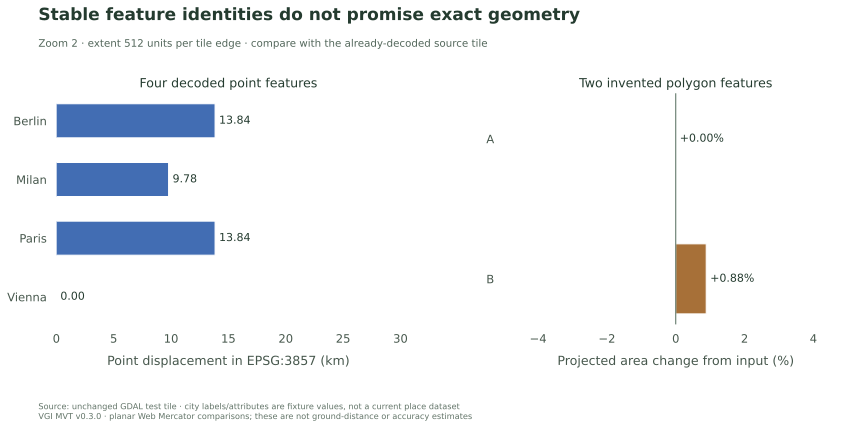

In [14]:
example.roundtrip_changes(measures, EXTENT)

### Check the bounded roundtrip

Require all six assigned identities, exact property preservation, valid geometries, declared single-zoom output, and the point rounding bound. Both input and output retain the test polygon's excluded hole centre at (10°E, 48°N); that local control is useful but not a general topology proof. A separate polygon area comparison reports the actual change instead of assuming equality.


In [15]:
%%sql checks <<
SELECT 'six decoded inputs retain two layers' AS check_name,
 (SELECT count(*)=6 AND count(DISTINCT layer)=2 FROM source_features) AS passed
UNION ALL SELECT 'four point and two polygon inputs',
 (SELECT count(*) FILTER(WHERE layer='cities')=4 AND count(*) FILTER(WHERE layer='regions')=2 FROM source_features)
UNION ALL SELECT 'original raw tile has no feature IDs',(SELECT count(feature_id)=0 FROM file_features)
UNION ALL SELECT 'assigned identities are unique',(SELECT count(*)=6 AND count(DISTINCT(layer,feature_id))=6 FROM source_features)
UNION ALL SELECT 'all assigned identities survive exactly once',(SELECT count(*)=6 AND count(DISTINCT(layer,feature_id))=6 FROM roundtrip)
UNION ALL SELECT 'no identity missing or added',NOT EXISTS(
 (SELECT layer,feature_id FROM source_features EXCEPT SELECT layer,feature_id FROM roundtrip)
 UNION ALL (SELECT layer,feature_id FROM roundtrip EXCEPT SELECT layer,feature_id FROM source_features))
UNION ALL SELECT 'all properties match',(SELECT bool_and(properties_equal) FROM measures)
UNION ALL SELECT 'output geometries valid and nonempty',(SELECT bool_and(ST_IsValid(geometry) AND NOT ST_IsEmpty(geometry)) FROM roundtrip)
UNION ALL SELECT 'only requested zoom emitted',(SELECT bool_and(z=2) FROM roundtrip)
UNION ALL SELECT 'declared output zoom matches request',
 (SELECT count(*)=2 AND bool_and(value::INTEGER=2) FROM output_metadata WHERE key IN('minzoom','maxzoom'))
UNION ALL SELECT 'point displacement within half-cell diagonal',
 (SELECT bool_and(isfinite(point_shift_m) AND point_shift_m>=0 AND point_shift_m<=sqrt(2)*40075016.685578488/(4*{{ EXTENT }}*2)+1e-6) FROM measures WHERE layer='cities')
UNION ALL SELECT 'polygon area remains finite and positive',
 (SELECT bool_and(isfinite(output_area_m2) AND output_area_m2>0) FROM measures WHERE layer='regions')
UNION ALL SELECT 'hole centre remains excluded',
 (SELECT count(*)=1 AND bool_and(NOT ST_Contains(s.geometry,ST_Point(10,48)) AND NOT ST_Contains(r.geometry,ST_Point(10,48)))
 FROM source_features s JOIN roundtrip r USING(layer,feature_id) WHERE s.layer='regions' AND s.properties->>'code'='A');


In [16]:
display(checks)
assert len(checks) == 13 and checks.passed.notna().all() and checks.passed.all()
prose(
    f"**All {len(checks)} roundtrip checks passed.** They preserve the feature/attribute contract "
    "while leaving coordinate changes visible."
)

,check_name,passed
0,six decoded inputs retain two layers,True
1,four point and two polygon inputs,True
2,original raw tile has no feature IDs,True
3,assigned identities are unique,True
4,all assigned identities survive exactly once,True
5,no identity missing or added,True
6,all properties match,True
7,output geometries valid and nonempty,True
8,only requested zoom emitted,True
9,declared output zoom matches request,True


**All 13 roundtrip checks passed.** They preserve the feature/attribute contract while leaving coordinate changes visible.

### Make the grid coarser

Change only `EXTENT` from **512 to 256** and Run All. The tile bytes decoded at the beginning, file/BLOB agreement, assigned IDs, properties and six-feature input/output populations should stay fixed. The point-displacement and polygon-area panels should change. Their fixed axes support direct comparison; the areas and distances have separate scales and units.

This is an additional encoding of an already quantized test tile. The measured differences do not quantify total error from the original design coordinates, much less real-world accuracy. Restore **512** for the default.


In [17]:
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
session.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-mvt](https://github.com/Query-farm/vgi-mvt)
